## Feature Extraction Sensing Schizophrenia Example


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')
import os
from google.colab import drive
drive.mount('/content/drive')

# Set style
sns.set_style('dark')
plt.rcParams['figure.figsize'] = (14, 6)

Mounted at /content/drive


In [2]:
# Load all datasets
base_dir = '/content/drive/MyDrive/Colab_Notebooks/Anna_JacobsonColabDrive/SensingIndividualized/cleaned_out'
participant_id = "00092"

location = pd.read_csv(os.path.join(base_dir, str(participant_id), "location_sample.csv"))
acceleration = pd.read_csv(os.path.join(base_dir, str(participant_id), "acceleration_sample.csv"))
battery = pd.read_csv(os.path.join(base_dir, str(participant_id), "battery_level_sample.csv"))
ema = pd.read_csv(os.path.join(base_dir, str(participant_id), "ema_response.csv"), index_col=False)

# location = pd.read_csv('/content/drive/MyDrive/Colab_Notebooks/Anna_JacobsonColabDrive/SensingIndividualized/testing_data/13_location_sample.csv')
# acceleration = pd.read_csv('/content/drive/MyDrive/Colab_Notebooks/Anna_JacobsonColabDrive/SensingIndividualized/testing_data/13_acceleration_sample.csv')
# battery = pd.read_csv('/content/drive/MyDrive/Colab_Notebooks/Anna_JacobsonColabDrive/SensingIndividualized/testing_data/13_battery_level_sample.csv')
# ema = pd.read_csv('/content/drive/MyDrive/Colab_Notebooks/Anna_JacobsonColabDrive/SensingIndividualized/testing_data/13_ema_response.csv', index_col=False)

# Convert once (only for dfs that actually have 'date')
for df in [acceleration, ema, location, battery]:
    if 'date' in df.columns:
        df['datetime'] = pd.to_datetime(df['date'], format='mixed', errors='coerce')

def count_days(df, col='datetime'):
    return df[col].dt.normalize().nunique()


print(f"Participant {participant_id} data coverage:")
print("Location days:", count_days(location, 'datetime'))
print("Acceleration days:", count_days(acceleration, 'datetime'))
print("Battery days:", count_days(battery, 'datetime'))
print("EMA days:", count_days(ema, 'datetime'))


Participant 00092 data coverage:
Location days: 100
Acceleration days: 100
Battery days: 100
EMA days: 93


In [3]:
# Basic cleaning and feature engineering for raw streams

def dedupe_and_sort(df, subset=None):
    df = df.dropna(subset=["date"]).copy()
    subset = subset or [c for c in df.columns if c != "participant_number"]
    df = df.drop_duplicates(subset=subset)
    df = df.sort_values("date").reset_index(drop=True)
    return df

acceleration = dedupe_and_sort(acceleration, subset=["timestamp", "x", "y", "z"])
#gyro = dedupe_and_sort(gyro, subset=["timestamp", "x", "y", "z"])
battery = dedupe_and_sort(battery, subset=["timestamp", "batteryPercent"])
location = dedupe_and_sort(location, subset=["timestamp", "latitude", "longitude", "speed"])
ema = dedupe_and_sort(ema, subset=["timestamp", "surveyId", "questionnaireType", "questionNumber", "response"])

acceleration["accel_mag"] = np.sqrt(acceleration["x"]**2 + acceleration["y"]**2 + acceleration["z"]**2)
#gyro["gyro_mag"] = np.sqrt(gyro["x"]**2 + gyro["y"]**2 + gyro["z"]**2)

if "speed" not in location.columns:
    location["speed"] = np.nan

print(acceleration.head())
print(ema[["questionnaireType", "questionNumber", "questionText"]].drop_duplicates().head(10))


          x         y         z                     date      timestamp  \
0  0.000000  0.000000  0.000000  2025-02-11 14:29:51.289  1739305791289   
1  0.021007  0.002521  0.008149  2025-02-11 14:29:51.481  1739305791481   
2 -0.004645 -0.014558 -0.019199  2025-02-11 14:29:51.679  1739305791679   
3  0.403520 -0.290682  0.257401  2025-02-11 14:29:51.873  1739305791873   
4  0.665350 -0.232100  0.089423  2025-02-11 14:29:52.068  1739305792068   

   participant_number                                      __source_file  \
0                  92  /content/drive/MyDrive/IndSensingData (1)/Data...   
1                  92  /content/drive/MyDrive/IndSensingData (1)/Data...   
2                  92  /content/drive/MyDrive/IndSensingData (1)/Data...   
3                  92  /content/drive/MyDrive/IndSensingData (1)/Data...   
4                  92  /content/drive/MyDrive/IndSensingData (1)/Data...   

                 datetime  accel_mag  
0 2025-02-11 14:29:51.289   0.000000  
1 2025-02-11 1

## Check for periods of missing data

In [4]:
import pandas as pd
import numpy as np

# ------------------------------
# 1) Ensure datetime column exists
# ------------------------------
for df in [acceleration, ema, location, battery]:
    if 'date' in df.columns:
        df['datetime'] = pd.to_datetime(df['date'], format='mixed', errors='coerce')

# ------------------------------
# 2) Compute expected samples per 15-min bin (75th percentile)
# ------------------------------
def expected_per_bin_75(df, datetime_col='datetime', freq='15min'):
    counts = df.set_index(datetime_col).resample(freq).size()
    expected = int(np.percentile(counts, 75))
    expected = max(expected, 1)  # avoid zero
    print(f"{df.columns[0]}: expected samples per {freq} = {expected}")
    return expected

# ------------------------------
# 3) Expand dataframe to full equally spaced dataset
# ------------------------------
def expand_to_full_bins(df, expected_per_bin, freq='15min', datetime_col='datetime'):
    df = df.dropna(subset=[datetime_col]).sort_values(datetime_col).copy()

    # full bin range
    start = df[datetime_col].min().floor(freq)
    end = df[datetime_col].max().ceil(freq)
    full_bins = pd.date_range(start, end, freq=freq)

    # assign bin
    df['bin'] = df[datetime_col].dt.floor(freq)

    # --- SMART STEP: uniform downsampling within each bin ---
    def downsample(group):
        T = len(group)
        if T <= expected_per_bin:
            return group

        idx = np.linspace(0, T - 1, expected_per_bin).astype(int)
        return group.iloc[idx]

    df = df.groupby('bin', group_keys=False).apply(downsample)

    # now assign slots AFTER downsampling
    df['slot'] = df.groupby('bin').cumcount()

    # build full grid
    full_index = pd.MultiIndex.from_product(
        [full_bins, range(expected_per_bin)],
        names=['bin', 'slot']
    )

    df_full = (
        df.set_index(['bin', 'slot'])
          .reindex(full_index)
          .reset_index()
    )

    # reconstruct equally spaced timestamps
    interval = pd.Timedelta(freq) / expected_per_bin
    df_full[datetime_col] = df_full['bin'] + df_full['slot'] * interval

    df_full = df_full.drop(columns=['bin', 'slot'])

    return df_full

# ------------------------------
# 4) Apply to each sensor
# ------------------------------
loc_expected = expected_per_bin_75(location)
location = expand_to_full_bins(location, loc_expected)

acc_expected = expected_per_bin_75(acceleration)
acceleration = expand_to_full_bins(acceleration, acc_expected)

bat_expected = expected_per_bin_75(battery)
battery = expand_to_full_bins(battery, bat_expected)


latitude: expected samples per 15min = 3
x: expected samples per 15min = 50
batteryPercent: expected samples per 15min = 1


In [7]:
acceleration.head(60)

,x,y,z,date,timestamp,participant_number,__source_file,datetime,accel_mag
0,0.000000,0.000000,0.000000,2025-02-11 14:29:51.289,1.739306e+12,92.0,/content/drive/MyDrive/IndSensingData (1)/Data...,2025-02-11 14:15:00,0.000000
1,0.021007,0.002521,0.008149,2025-02-11 14:29:51.481,1.739306e+12,92.0,/content/drive/MyDrive/IndSensingData (1)/Data...,2025-02-11 14:15:18,0.022673
2,-0.004645,-0.014558,-0.019199,2025-02-11 14:29:51.679,1.739306e+12,92.0,/content/drive/MyDrive/IndSensingData (1)/Data...,2025-02-11 14:15:36,0.024538
3,0.403520,-0.290682,0.257401,2025-02-11 14:29:51.873,1.739306e+12,92.0,/content/drive/MyDrive/IndSensingData (1)/Data...,2025-02-11 14:15:54,0.559982
4,0.665350,-0.232100,0.089423,2025-02-11 14:29:52.068,1.739306e+12,92.0,/content/drive/MyDrive/IndSensingData (1)/Data...,2025-02-11 14:16:12,0.710322
5,-0.937894,0.620389,-0.457261,2025-02-11 14:29:52.267,1.739306e+12,92.0,/content/drive/MyDrive/IndSensingData (1)/Data...,2025-02-11 14:16:30,1.213925
6,-0.966026,0.681014,-0.324525,2025-02-11 14:29:52.459,1.739306e+12,92.0,/content/drive/MyDrive/IndSensingData (1)/Data...,2025-02-11 14:16:48,1.225684
7,-0.223310,-0.046915,-0.135679,2025-02-11 14:29:52.656,1.739306e+12,92.0,/content/drive/MyDrive/IndSensingData (1)/Data...,2025-02-11 14:17:06,0.265476
8,-0.019034,0.084139,0.119549,2025-02-11 14:29:52.850,1.739306e+12,92.0,/content/drive/MyDrive/IndSensingData (1)/Data...,2025-02-11 14:17:24,0.147423
9,0.068351,0.151675,-0.095730,2025-02-11 14:29:53.045,1.739306e+12,92.0,/content/drive/MyDrive/IndSensingData (1)/Data...,2025-02-11 14:17:42,0.191941


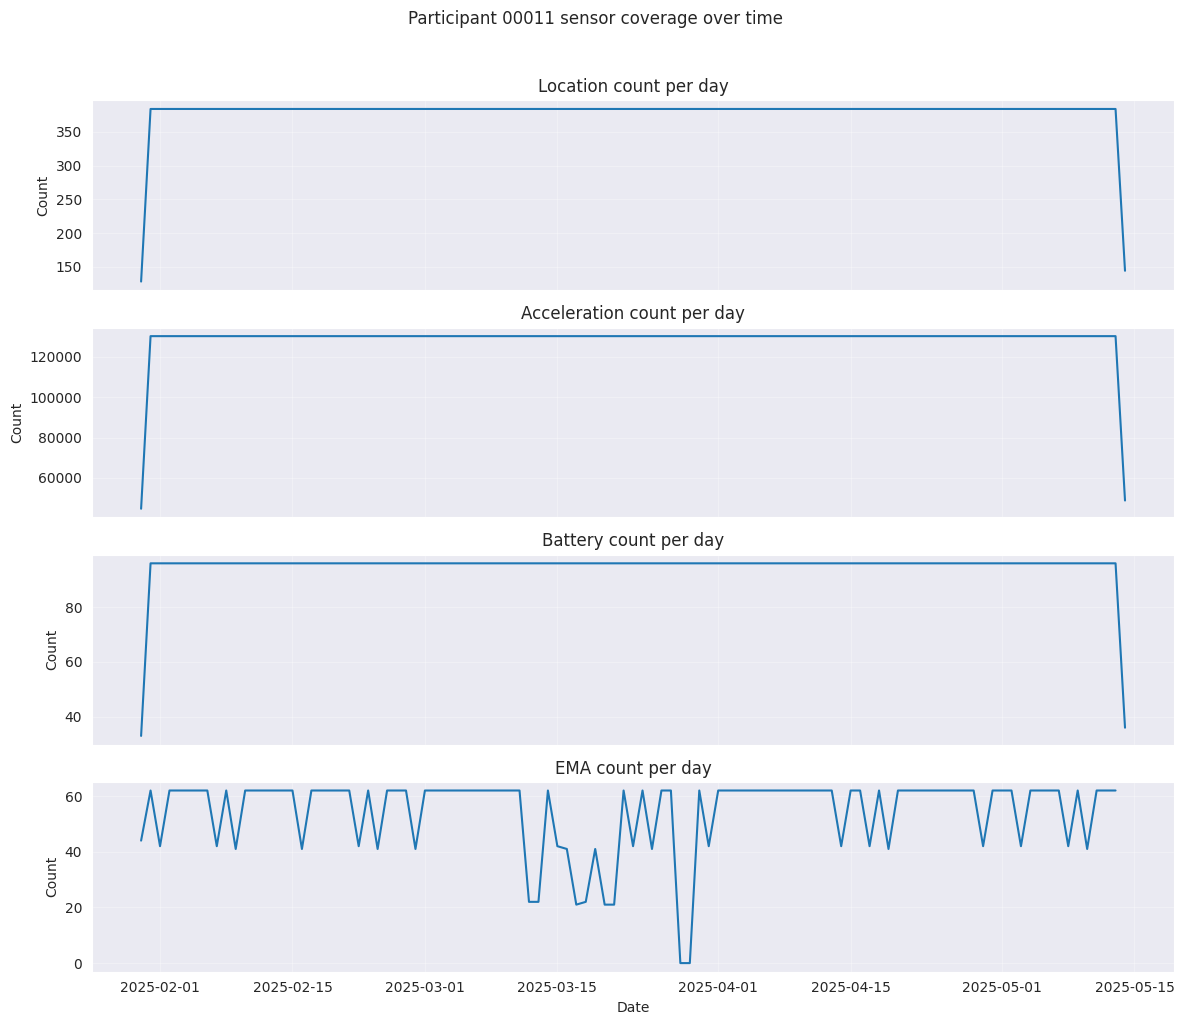

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

daily = {
    "Location": location.set_index('datetime').resample('D').size(),
    "Acceleration": acceleration.set_index('datetime').resample('D').size(),
    "Battery": battery.set_index('datetime').resample('D').size(),
    "EMA": ema.set_index('datetime').resample('D').size(),
}

# 4) Plot
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

for ax, (name, series) in zip(axes, daily.items()):
    ax.plot(series.index, series.values, linewidth=1.5)
    ax.set_title(f"{name} count per day")
    ax.set_ylabel("Count")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")
plt.suptitle(f"Participant {participant_id} sensor coverage over time", y=1.02)
plt.tight_layout()
plt.show()


## Create Categories for EMA data

In [ ]:
import pandas as pd
import numpy as np


# 1️⃣ Categorize questions
def categorize_question(q):
    if pd.isna(q):
        return np.nan
    if any(phrase in q for phrase in [
        "I would rather have been doing something else.",
        "I have felt unmotivated.",
        "I have felt emotionally flat, numb, or blank.",
        "I have experienced difficulty expressing my emotions or thoughts.",
        "I have not wanted to socialize."
    ]):
        return "Negative symptom"
    if any(phrase in q for phrase in [
        "to what degree have you had any unusual experiences?",
        "I have felt detached from reality.",
        "I have felt I possess special powers or abilities.",
        "I have felt I am receiving special messages.",
        "I have felt suspicious of others."
    ]):
        return "Positive symptom"
    if any(phrase in q for phrase in [
        "I have found it easy to concentrate.",
        "I have experienced racing thoughts.",
        "I have found it easy to make decisions.",
        "I have experienced difficulty thinking clearly.",
        "I have had trouble remembering things."
    ]):
        return "Cognitive symptom"
    if any(phrase in q for phrase in [
        "I have been able to complete my daily activities.",
        "I have been able to interact with others.",
        "I have been able to manage my physical and mental health."
    ]):
        return "Functional outcome"
    if "thoughts of hurting myself" in q:
        return "Suicide ideation/self-harm"
    if "Do you intend to end your life now or in the near future?" in q:
        return "Suicide risk follow-up"
    if "Last night I had trouble with sleep." in q:
        return "Sleep quality"
    if "I took my medications for psychotic symptoms today." in q:
        return "Medication adherence"
    return np.nan

# Categorize questions
ema['ema_category'] = ema['questionText'].apply(categorize_question)
ema['response'] = pd.to_numeric(ema['response'], errors='coerce')

# Reverse coding
reverse_items = [
  "In the past 4 hours, I have found it easy to concentrate.",
  "In the past 4 hours, I have found it easy to make decisions."
]

ema['reverse_flag'] = ema['questionText'].isin(reverse_items)

ema['response'] = np.where(
    ema['reverse_flag'],
    (0 + 100) - ema['response'],
    ema['response']
)


### For participants that have multiple numbers (I tested this)
ema['datetime'] = pd.to_datetime(ema['datetime'])
ema = ema.sort_values(['datetime'])

ema['time_diff'] = ema['datetime'].diff().dt.total_seconds().div(60)
ema['new_survey'] = (ema['time_diff'] > 60) | (ema['time_diff'].isna())

# Assign survey instance ID
ema['surveyId'] = ema['new_survey'].cumsum()


# Group by survey_id and category, take mean response per survey
grouped = ema.groupby(['surveyId', 'ema_category'])['response'].mean().reset_index()

# Pivot to wide format
wide_ema = grouped.pivot(index='surveyId', columns='ema_category', values='response').reset_index()

# Optional: merge first datetime per survey
first_timestamps = ema.groupby('surveyId')['datetime'].min().reset_index()
wide_ema = wide_ema.merge(first_timestamps, on='surveyId')

# Reorder columns to have datetime first
cols = ['datetime', 'surveyId'] + [c for c in wide_ema.columns if c not in ['datetime','surveyId']]
wide_ema = wide_ema[cols]

print(wide_ema.head())


             datetime  surveyId  Cognitive symptom  Functional outcome  \
0 2025-01-30 15:40:26         1          61.575886           38.131795   
1 2025-01-30 19:31:32         2          73.513959           59.130937   
2 2025-01-31 09:31:48         3          66.532391           74.427784   
3 2025-01-31 14:30:52         4          67.152975           54.939274   
4 2025-01-31 20:01:12         5          56.031459           45.644126   

   Medication adherence  Negative symptom  Positive symptom  Sleep quality  \
0                   NaN         66.161499         45.821047      77.013550   
1                   NaN         62.535983         36.887906      77.830108   
2                   NaN         62.029717         34.871008      65.050980   
3                   NaN         56.411800         34.038119            NaN   
4                   NaN         44.236925         28.991793            NaN   

   Suicide ideation/self-harm  Suicide risk follow-up  
0                    1.767760 

In [ ]:
# ## AGGREGATED BY DAY #####
# # Add date column
# ema['date'] = ema['datetime'].dt.date

# # Mean response per day and EMA category
# daily_grouped = (
#     ema
#     .dropna(subset=['ema_category'])
#     .groupby(['date', 'ema_category'])['response']
#     .mean()
#     .reset_index()
# )

# # Pivot to wide daily format
# wide_ema = (
#     daily_grouped
#     .pivot(index='date', columns='ema_category', values='response')
#     .reset_index()
# )

# print(wide_ema.head())
# ############

In [ ]:
wide_ema.shape

(273, 10)

In [ ]:
# ###### AGGREGATED BY DAY
# import numpy as np
# import pandas as pd

# # -----------------------------
# # Step 0: Sort sensor DataFrames
# # -----------------------------
# acceleration = acceleration.copy()
# battery = battery.copy()
# location = location.copy()
# wide_ema = wide_ema.copy()

# acceleration['datetime'] = pd.to_datetime(acceleration['datetime'])
# battery['datetime'] = pd.to_datetime(battery['datetime'])
# location['datetime'] = pd.to_datetime(location['datetime'])
# wide_ema['date'] = pd.to_datetime(wide_ema['date'])

# acceleration = acceleration.sort_values('datetime')
# battery = battery.sort_values('datetime')
# location = location.sort_values('datetime')

# # -----------------------------
# # Step 1: Merge sensor streams for combined head
# # -----------------------------
# merged_combined = pd.merge_asof(
#     acceleration,
#     battery[['datetime', 'batteryPercent']],
#     on='datetime',
#     direction='backward',
#     tolerance=pd.Timedelta('10min')
# )

# merged_combined = pd.merge_asof(
#     merged_combined,
#     location[['datetime', 'latitude', 'longitude', 'speed']],
#     on='datetime',
#     direction='backward',
#     tolerance=pd.Timedelta('10min')
# )

# merged_combined['batteryPercent'] = merged_combined['batteryPercent'].ffill()
# merged_combined['latitude'] = merged_combined['latitude'].ffill()
# merged_combined['longitude'] = merged_combined['longitude'].ffill()
# merged_combined['speed'] = merged_combined['speed'].fillna(0.0)

# # -----------------------------
# # Step 2: Helper functions
# # -----------------------------
# def safe_array(x):
#     if x is None:
#         return np.array([], dtype=np.float32)
#     arr = pd.to_numeric(x, errors='coerce').dropna().to_numpy(dtype=np.float32)
#     return arr


# def pad_or_trim_2d(seq, target_len):
#     if seq is None or len(seq) == 0 or target_len == 0:
#         return np.full((1, 1), np.nan, dtype=np.float32)

#     ts = np.asarray(seq, dtype=np.float32)

#     if ts.ndim == 1:
#         ts = ts[:, None]

#     T, F = ts.shape

#     if T > target_len:
#         idx = np.linspace(0, T - 1, target_len).astype(int)
#         ts = ts[idx]
#         T = target_len

#     out = np.full((target_len, F), np.nan, dtype=np.float32)
#     out[:T] = ts[:T]

#     return out


# TARGET_LEN_CAP = 8192

# label_cols = [
#     "Negative symptom",
#     "Cognitive symptom",
#     "Positive symptom"
# ]

# # -----------------------------
# # Step 3: Loop over daily EMA outcomes
# # Use sensors from prior calendar day
# # -----------------------------
# features_accel = []
# features_battery = []
# features_gps = []
# features_speed = []
# features_combined = []
# labels_list = []
# dates_list = []

# for _, r in wide_ema.iterrows():

#     current_day = pd.to_datetime(r['date']).normalize()

#     # Prior calendar day:
#     # outcome date 2025-02-11 uses sensors from
#     # 2025-02-10 00:00 to 2025-02-11 00:00
#     feature_start = current_day - pd.Timedelta(days=1)
#     feature_end = current_day

#     accel_window = acceleration[
#         (acceleration['datetime'] >= feature_start) &
#         (acceleration['datetime'] < feature_end)
#     ]

#     battery_window = battery[
#         (battery['datetime'] >= feature_start) &
#         (battery['datetime'] < feature_end)
#     ]

#     location_window = location[
#         (location['datetime'] >= feature_start) &
#         (location['datetime'] < feature_end)
#     ]

#     combined_window = merged_combined[
#         (merged_combined['datetime'] >= feature_start) &
#         (merged_combined['datetime'] < feature_end)
#     ]

#     # Skip day if no sensor data
#     if (
#         accel_window.empty and
#         battery_window.empty and
#         location_window.empty and
#         combined_window.empty
#     ):
#         continue

#     # -----------------------------
#     # Separate sensor streams
#     # -----------------------------
#     accel_cols = ['accel_mag', 'x', 'y', 'z']
#     gps_cols = ['latitude', 'longitude']

#     accel_ts = accel_window[accel_cols].apply(
#         pd.to_numeric, errors='coerce'
#     ).to_numpy(dtype=np.float32)

#     battery_ts = battery_window[['batteryPercent']].apply(
#         pd.to_numeric, errors='coerce'
#     ).to_numpy(dtype=np.float32)

#     gps_ts = location_window[gps_cols].apply(
#         pd.to_numeric, errors='coerce'
#     ).to_numpy(dtype=np.float32)

#     speed_ts = location_window[['speed']].apply(
#         pd.to_numeric, errors='coerce'
#     ).to_numpy(dtype=np.float32)

#     features_accel.append(
#         pad_or_trim_2d(accel_ts, min(TARGET_LEN_CAP, len(accel_ts)))
#     )

#     features_battery.append(
#         pad_or_trim_2d(battery_ts, min(TARGET_LEN_CAP, len(battery_ts)))
#     )

#     features_gps.append(
#         pad_or_trim_2d(gps_ts, min(TARGET_LEN_CAP, len(gps_ts)))
#     )

#     features_speed.append(
#         pad_or_trim_2d(speed_ts, min(TARGET_LEN_CAP, len(speed_ts)))
#     )

#     # -----------------------------
#     # Combined head
#     # -----------------------------
#     combined_cols = [
#         'accel_mag',
#         'x',
#         'y',
#         'z',
#         'batteryPercent',
#         'latitude',
#         'longitude',
#         'speed'
#     ]

#     ts_combined = combined_window[combined_cols].apply(
#         pd.to_numeric, errors='coerce'
#     ).to_numpy(dtype=np.float32)

#     features_combined.append(
#         pad_or_trim_2d(ts_combined, min(TARGET_LEN_CAP, len(ts_combined)))
#     )

#     # Labels and dates
#     labels_list.append(r[label_cols].to_numpy(dtype=np.float32))
#     dates_list.append(current_day)

# # -----------------------------
# # Step 4: Save to .npz
# # -----------------------------
# np.savez(
#     f'/content/drive/MyDrive/Colab_Notebooks/Anna_JacobsonColabDrive/SensingIndividualized/deeplearning_data/pred/participant_{participant_id}_prior_day.npz',
#     accel=np.array(features_accel, dtype=object),
#     battery=np.array(features_battery, dtype=object),
#     gps=np.array(features_gps, dtype=object),
#     speed=np.array(features_speed, dtype=object),
#     combined=np.array(features_combined, dtype=object),
#     labels=np.stack(labels_list, axis=0).astype(np.float32),
#     dates=np.array(pd.to_datetime(dates_list).astype(str), dtype=object),
#     allow_pickle=True
# )

# print("Saved dataset using prior-day sensor streams")
# print("Number of daily samples:", len(labels_list))
# print("Example combined shape:", features_combined[0].shape)

In [ ]:
import numpy as np
import pandas as pd

# -----------------------------
# Step 0: Sort sensor DataFrames
# -----------------------------
acceleration = acceleration.sort_values('datetime')
battery = battery.sort_values('datetime')
location = location.sort_values('datetime')

# -----------------------------
# Step 1: Merge sensor streams ONLY for combined head
# -----------------------------
merged_combined = pd.merge_asof(
    acceleration,
    battery[['datetime','batteryPercent']],
    on='datetime',
    direction='backward',
    tolerance=pd.Timedelta('10min')
)
merged_combined = pd.merge_asof(
    merged_combined,
    location[['datetime','latitude','longitude','speed']],
    on='datetime',
    direction='backward',
    tolerance=pd.Timedelta('10min')
)

# Forward-fill missing values in merged for combined head
merged_combined['batteryPercent'] = merged_combined['batteryPercent'].fillna(method='ffill')
merged_combined['latitude'] = merged_combined['latitude'].fillna(method='ffill')
merged_combined['longitude'] = merged_combined['longitude'].fillna(method='ffill')
merged_combined['speed'] = merged_combined['speed'].fillna(0.0)

# -----------------------------
# Step 2: Helper functions
# -----------------------------
def safe_array(x):
    """Convert sequence or scalar to np.array, handle None/NaN."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return np.array([], dtype=np.float32)
    arr = np.asarray(x, dtype=np.float32)
    if arr.ndim == 0:
        return np.array([], dtype=np.float32)
    return arr

def pad_or_trim_2d(seq, target_len):

    if seq is None or len(seq) == 0:
        return np.full((target_len, 1), np.nan, dtype=np.float32)

    ts = np.asarray(seq, dtype=np.float32)

    if ts.ndim == 1:
        ts = ts[:, None]

    T, F = ts.shape

    out = np.full((target_len, F), np.nan, dtype=np.float32)

    # --- uniform downsampling if too long ---
    if T > target_len:
        idx = np.linspace(0, T - 1, target_len).astype(int)
        ts = ts[idx]
        T = target_len

    L = min(T, target_len)
    out[:L] = ts[:L]

    return out

LOOKBACK = "24H"
TARGET_LEN_CAP = 8192
label_cols = ["Negative symptom", "Cognitive symptom", "Positive symptom"]

# -----------------------------
# Step 3: Loop over EMA windows
# -----------------------------
features_accel = []
features_battery = []
features_gps = []
features_speed = []
features_combined = []
labels_list = []
datetimes_list = []

ema_window = pd.Timedelta("4H")
lookback_window = pd.Timedelta(LOOKBACK)

for _, r in wide_ema.iterrows():
    t = r['datetime']

    # ----- Extract original sensor data in EMA window (exclude t) -----
    ema_start = t - ema_window          # start of EMA recall window
    feature_end = ema_start             # must exclude EMA window
    feature_start = ema_start - lookback_window

    # ----- Extract original sensor data (exclude EMA window, then apply lookback) -----
    accel_window = acceleration[
        (acceleration['datetime'] >= feature_start) &
        (acceleration['datetime'] < feature_end)
    ]

    battery_window = battery[
        (battery['datetime'] >= feature_start) &
        (battery['datetime'] < feature_end)
    ]

    location_window = location[
        (location['datetime'] >= feature_start) &
        (location['datetime'] < feature_end)
    ]

    # Convert to arrays
    accel_seq = safe_array(accel_window['accel_mag'])
    x_seq = safe_array(accel_window['x'])
    y_seq = safe_array(accel_window['y'])
    z_seq = safe_array(accel_window['z'])
    battery_seq = safe_array(battery_window['batteryPercent'])
    speed_seq = safe_array(location_window['speed'])
    latitude_seq = safe_array(location_window['latitude'])
    longitude_seq = safe_array(location_window['longitude'])

    # Skip EMA if all sequences are empty
    if len(accel_seq) == 0 and len(battery_seq) == 0 and len(speed_seq) == 0:
        continue

    # -----------------------------
    # Keep each sensor stream variable-length
    # -----------------------------
    # Keep each sensor stream variable-length, but cap at TARGET_LEN_CAP
    accel_ts = np.stack([accel_seq, x_seq, y_seq, z_seq], axis=1)
    battery_ts = battery_seq[:, None]
    gps_ts = np.stack([latitude_seq, longitude_seq], axis=1)
    speed_ts = speed_seq[:, None]

    features_accel.append(pad_or_trim_2d(accel_ts, min(TARGET_LEN_CAP, accel_ts.shape[0])))
    features_battery.append(pad_or_trim_2d(battery_ts, min(TARGET_LEN_CAP, battery_ts.shape[0])))
    features_gps.append(pad_or_trim_2d(gps_ts, min(TARGET_LEN_CAP, gps_ts.shape[0])))
    features_speed.append(pad_or_trim_2d(speed_ts, min(TARGET_LEN_CAP, speed_ts.shape[0])))

    # -----------------------------
    # Prepare combined feature for Chronos (merged + padded)
    # -----------------------------
    combined_window = merged_combined[
        (merged_combined['datetime'] >= feature_start) &
        (merged_combined['datetime'] < feature_end)
    ]

    ts_combined = np.concatenate([
        np.stack([
            combined_window['accel_mag'],
            combined_window['x'],
            combined_window['y'],
            combined_window['z']
        ], axis=1),
        combined_window['batteryPercent'].to_numpy()[:, None],
        np.stack([
            combined_window['latitude'],
            combined_window['longitude']
        ], axis=1),
        combined_window['speed'].to_numpy()[:, None]
    ], axis=1)

    features_combined.append(pad_or_trim_2d(ts_combined, min(TARGET_LEN_CAP, ts_combined.shape[0])))

    # Labels and datetimes
    labels_list.append(r[label_cols].to_numpy(dtype=np.float32))
    datetimes_list.append(t)

# -----------------------------
# Step 4: Save to .npz
# -----------------------------
np.savez(
    f'/content/drive/MyDrive/Colab_Notebooks/Anna_JacobsonColabDrive/SensingIndividualized/deeplearning_data/pred/participant_{participant_id}_24h.npz',
    accel=np.array(features_accel, dtype=object),
    battery=np.array(features_battery, dtype=object),
    gps=np.array(features_gps, dtype=object),
    speed=np.array(features_speed, dtype=object),
    combined=np.array(features_combined, dtype=object),
    labels=np.stack(labels_list, axis=0).astype(np.float32),
    datetimes=np.array(pd.to_datetime(datetimes_list).astype(str), dtype=object),
    allow_pickle=True
)

print("Saved Chronos dataset with separate sensor streams + combined head")
print("Example combined shape:", features_combined[0].shape)

Saved Chronos dataset with separate sensor streams + combined head
Example combined shape: (8192, 8)


In [ ]:
# import numpy as np
# import pandas as pd

# # -----------------------------
# # Step 0: Sort sensor DataFrames
# # -----------------------------
# acceleration = acceleration.sort_values('datetime')
# battery = battery.sort_values('datetime')
# location = location.sort_values('datetime')

# # -----------------------------
# # Step 1: Merge sensor streams ONLY for combined head
# # -----------------------------
# merged_combined = pd.merge_asof(
#     acceleration,
#     battery[['datetime','batteryPercent']],
#     on='datetime',
#     direction='backward',
#     tolerance=pd.Timedelta('10min')
# )
# merged_combined = pd.merge_asof(
#     merged_combined,
#     location[['datetime','latitude','longitude','speed']],
#     on='datetime',
#     direction='backward',
#     tolerance=pd.Timedelta('10min')
# )

# # Forward-fill missing values in merged for combined head
# merged_combined['batteryPercent'] = merged_combined['batteryPercent'].fillna(method='ffill')
# merged_combined['latitude'] = merged_combined['latitude'].fillna(method='ffill')
# merged_combined['longitude'] = merged_combined['longitude'].fillna(method='ffill')
# merged_combined['speed'] = merged_combined['speed'].fillna(0.0)

# # -----------------------------
# # Step 2: Helper functions
# # -----------------------------
# def safe_array(x):
#     """Convert sequence or scalar to np.array, handle None/NaN."""
#     if x is None or (isinstance(x, float) and np.isnan(x)):
#         return np.array([], dtype=np.float32)
#     arr = np.asarray(x, dtype=np.float32)
#     if arr.ndim == 0:
#         return np.array([], dtype=np.float32)
#     return arr

# def pad_or_trim_2d(seq, target_len):

#     if seq is None or len(seq) == 0:
#         return np.full((target_len, 1), np.nan, dtype=np.float32)

#     ts = np.asarray(seq, dtype=np.float32)

#     if ts.ndim == 1:
#         ts = ts[:, None]

#     T, F = ts.shape

#     out = np.full((target_len, F), np.nan, dtype=np.float32)

#     # --- uniform downsampling if too long ---
#     if T > target_len:
#         idx = np.linspace(0, T - 1, target_len).astype(int)
#         ts = ts[idx]
#         T = target_len

#     L = min(T, target_len)
#     out[:L] = ts[:L]

#     return out

# LOOKBACK = "4H"
# TARGET_LEN_CAP = 8192
# label_cols = ["Negative symptom", "Cognitive symptom", "Positive symptom"]

# # -----------------------------
# # Step 3: Loop over EMA windows
# # -----------------------------
# features_accel = []
# features_battery = []
# features_gps = []
# features_speed = []
# features_combined = []
# labels_list = []
# datetimes_list = []

# ema_window = pd.Timedelta("4H")
# lookback_window = pd.Timedelta(LOOKBACK)

# for _, r in wide_ema.iterrows():
#     t = r['datetime']

#     # # ----- Extract original sensor data in EMA window (exclude t) -----
#     # ema_start = t - ema_window          # start of EMA recall window
#     # # feature_end = ema_start             # must exclude EMA window
#     # # feature_start = ema_start - lookback_window
#     # # DETECT
#     # feature_start = ema_start
#     # feature_end = t


#     feature_start = t
#     feature_end = t + lookback_window

#     # ----- Extract original sensor data (exclude EMA window, then apply lookback) -----
#     accel_window = acceleration[
#         (acceleration['datetime'] >= feature_start) &
#         (acceleration['datetime'] < feature_end)
#     ]

#     battery_window = battery[
#         (battery['datetime'] >= feature_start) &
#         (battery['datetime'] < feature_end)
#     ]

#     location_window = location[
#         (location['datetime'] >= feature_start) &
#         (location['datetime'] < feature_end)
#     ]

#     # Convert to arrays
#     accel_seq = safe_array(accel_window['accel_mag'])
#     x_seq = safe_array(accel_window['x'])
#     y_seq = safe_array(accel_window['y'])
#     z_seq = safe_array(accel_window['z'])
#     battery_seq = safe_array(battery_window['batteryPercent'])
#     speed_seq = safe_array(location_window['speed'])
#     latitude_seq = safe_array(location_window['latitude'])
#     longitude_seq = safe_array(location_window['longitude'])

#     # Skip EMA if all sequences are empty
#     if len(accel_seq) == 0 and len(battery_seq) == 0 and len(speed_seq) == 0:
#         continue

#     # -----------------------------
#     # Keep each sensor stream variable-length
#     # -----------------------------
#     # Keep each sensor stream variable-length, but cap at TARGET_LEN_CAP
#     accel_ts = np.stack([accel_seq, x_seq, y_seq, z_seq], axis=1)
#     battery_ts = battery_seq[:, None]
#     gps_ts = np.stack([latitude_seq, longitude_seq], axis=1)
#     speed_ts = speed_seq[:, None]

#     features_accel.append(pad_or_trim_2d(accel_ts, min(TARGET_LEN_CAP, accel_ts.shape[0])))
#     features_battery.append(pad_or_trim_2d(battery_ts, min(TARGET_LEN_CAP, battery_ts.shape[0])))
#     features_gps.append(pad_or_trim_2d(gps_ts, min(TARGET_LEN_CAP, gps_ts.shape[0])))
#     features_speed.append(pad_or_trim_2d(speed_ts, min(TARGET_LEN_CAP, speed_ts.shape[0])))

#     # -----------------------------
#     # Prepare combined feature for Chronos (merged + padded)
#     # -----------------------------
#     combined_window = merged_combined[
#         (merged_combined['datetime'] >= feature_start) &
#         (merged_combined['datetime'] < feature_end)
#     ]

#     ts_combined = np.concatenate([
#         np.stack([
#             combined_window['accel_mag'],
#             combined_window['x'],
#             combined_window['y'],
#             combined_window['z']
#         ], axis=1),
#         combined_window['batteryPercent'].to_numpy()[:, None],
#         np.stack([
#             combined_window['latitude'],
#             combined_window['longitude']
#         ], axis=1),
#         combined_window['speed'].to_numpy()[:, None]
#     ], axis=1)

#     features_combined.append(pad_or_trim_2d(ts_combined, min(TARGET_LEN_CAP, ts_combined.shape[0])))

#     # Labels and datetimes
#     labels_list.append(r[label_cols].to_numpy(dtype=np.float32))
#     datetimes_list.append(t)

# # -----------------------------
# # Step 4: Save to .npz
# # -----------------------------
# np.savez(
#     f'/content/drive/MyDrive/Colab_Notebooks/Anna_JacobsonColabDrive/SensingIndividualized/deeplearning_data/pred/participant_{participant_id}_4h_later.npz',
#     accel=np.array(features_accel, dtype=object),
#     battery=np.array(features_battery, dtype=object),
#     gps=np.array(features_gps, dtype=object),
#     speed=np.array(features_speed, dtype=object),
#     combined=np.array(features_combined, dtype=object),
#     labels=np.stack(labels_list, axis=0).astype(np.float32),
#     datetimes=np.array(pd.to_datetime(datetimes_list).astype(str), dtype=object),
#     allow_pickle=True
# )

# print("Saved Chronos dataset with separate sensor streams + combined head")
# print("Example combined shape:", features_combined[0].shape)

(96, 1)


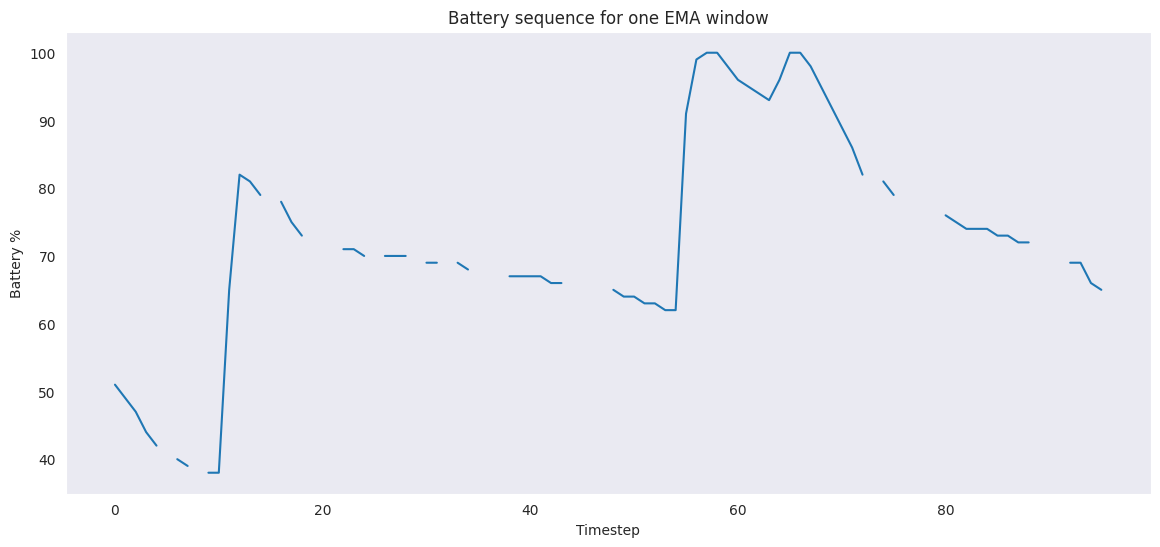

In [ ]:
sample_idx = 2
battery_sample = features_battery[sample_idx]  # shape (T,1), variable length
print(battery_sample.shape)  # should be ~16 or whatever the EMA window contains

import matplotlib.pyplot as plt

plt.plot(battery_sample)
plt.title("Battery sequence for one EMA window")
plt.xlabel("Timestep")
plt.ylabel("Battery %")
plt.show()

(8192, 4)


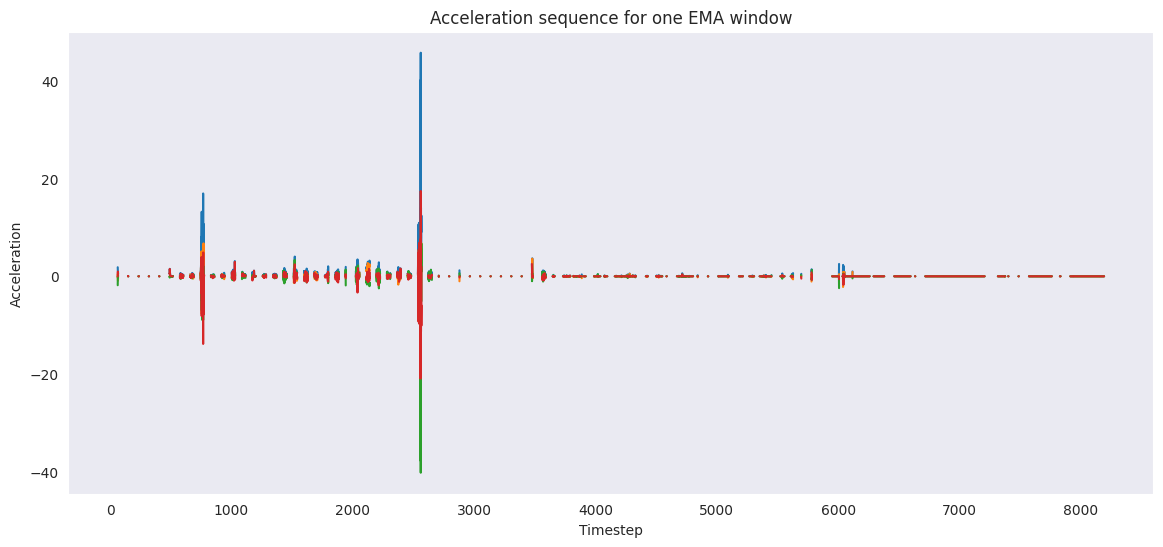

In [ ]:
sample_idx = 89
battery_sample = features_accel[sample_idx]  # shape (T,1), variable length
print(battery_sample.shape)  # should be ~16 or whatever the EMA window contains

import matplotlib.pyplot as plt

plt.plot(battery_sample)
plt.title("Acceleration sequence for one EMA window")
plt.xlabel("Timestep")
plt.ylabel("Acceleration")
plt.show()

(288, 2)


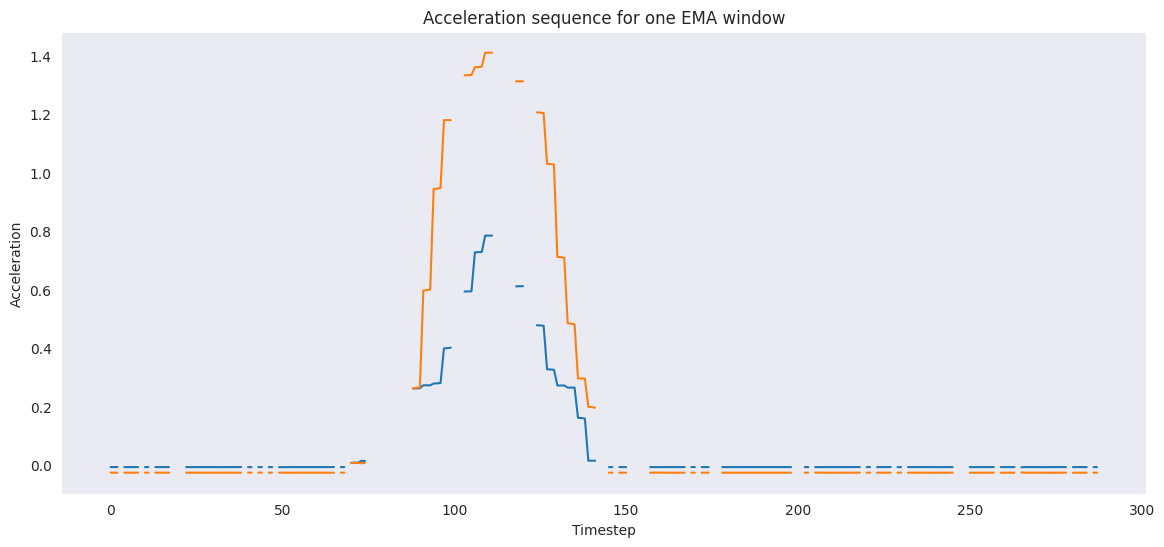

In [ ]:
sample_idx = 89
battery_sample = features_gps[sample_idx]  # shape (T,1), variable length
print(battery_sample.shape)  # should be ~16 or whatever the EMA window contains

import matplotlib.pyplot as plt

plt.plot(battery_sample)
plt.title("Acceleration sequence for one EMA window")
plt.xlabel("Timestep")
plt.ylabel("Acceleration")
plt.show()